# 04 · Model Routing and Typed Output

Until now the generator was a stand-in. A real RAG system calls a language model, and two engineering
problems appear the moment it does:

1. **Which model, from which provider, and what happens when it fails?** Providers differ in client
   libraries, message formats, error types and prices, and any of them can time out or throttle you.
   **LiteLLM** gives one calling convention for all of them, plus retries and fallbacks.
2. **Can you trust the shape of what comes back?** A model returns *text*. Your code needs a typed object
   with a verified answer, citations that exist and a refusal flag that is a boolean.
   **Pydantic** turns the model's output into a validated object or a precise error you can feed back to it.

Everything here runs offline: LiteLLM can return a canned `mock_response` through the real call path, so the
routing, error handling and cost code is the code you would run in production, and no key is needed.
Where a hosted model would be called, the cell is optional and guarded by an environment variable.

**You will learn**
1. One interface for many models with LiteLLM, and how a model string selects the provider
2. Retries and fallbacks to a second model when the first fails
3. Counting tokens and estimating cost per question
4. Pydantic v2 models for requests and responses, and what a validation error looks like
5. Structured model output: validate, feed the error back, retry, and measure how often that rescues a bad answer
6. A RAG answer schema whose citations are checked against the passages that were actually retrieved

### Picture: three layers between your code and a model

Read it left to right. Your code makes **one call**; LiteLLM turns it into the call each provider expects and, if the
first deployment fails, retries and then falls back to a second one. What comes back is still only text, so the last
layer (Pydantic) turns it into a validated object, or into a precise error you can send back.

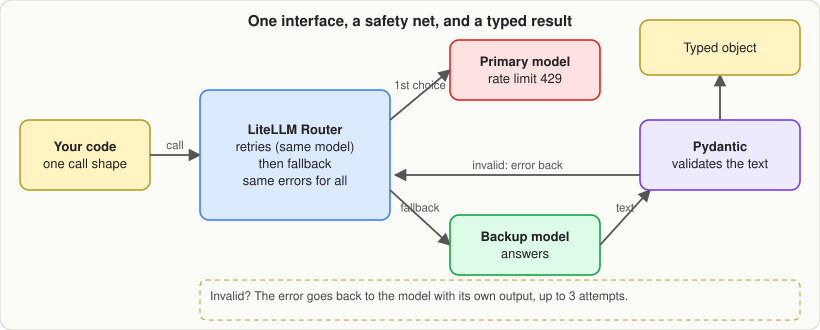

In [1]:
from IPython.display import SVG, display
import html as _h

_COL = {  # fill, stroke  (light cards with dark text: readable in light and dark themes)
    "gold": ("#fff4c2", "#b89d28"), "blue": ("#dbeafe", "#3b82f6"), "green": ("#dcfce7", "#16a34a"),
    "red": ("#fee2e2", "#dc2626"), "grey": ("#f1f1f4", "#8a8aa0"), "violet": ("#ede9fe", "#7c3aed"),
}

def diagram(width, height, items, title=None):
    # items: ("box", x, y, w, h, "text\nmore text", colour) | ("arrow", x1, y1, x2, y2, "label") |
    #        ("text", x, y, "text", size, "start|middle|end") | ("note", x, y, w, h, "text")
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" width="100%" '
           f'font-family="Helvetica, Arial, sans-serif">',
           '<defs><marker id="ah" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" '
           'orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="#555"/></marker></defs>',
           f'<rect width="{width}" height="{height}" rx="12" fill="#fbfbf8" stroke="#d8d8cf"/>']
    if title:
        out.append(f'<text x="{width / 2}" y="26" text-anchor="middle" font-size="15" font-weight="700" fill="#222">{_h.escape(title)}</text>')
    for it in items:
        kind = it[0]
        if kind == "box":
            _, x, y, w, h, text, col = it
            fill, stroke = _COL[col]
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="9" fill="{fill}" stroke="{stroke}" stroke-width="1.6"/>')
            lines = text.split("\n")
            y0 = y + h / 2 - (len(lines) - 1) * 8.5 + 4.5
            for k, ln in enumerate(lines):
                bold = ' font-weight="700"' if k == 0 and len(lines) > 1 else ""
                out.append(f'<text x="{x + w / 2}" y="{y0 + k * 17}" text-anchor="middle" font-size="13" fill="#222"{bold}>{_h.escape(ln)}</text>')
        elif kind == "arrow":
            _, x1, y1, x2, y2, label = it
            out.append(f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="#555" stroke-width="1.8" marker-end="url(#ah)"/>')
            if label:
                out.append(f'<text x="{(x1 + x2) / 2}" y="{(y1 + y2) / 2 - 6}" text-anchor="middle" font-size="11.5" fill="#555">{_h.escape(label)}</text>')
        elif kind == "text":
            _, x, y, text, size, anchor = it
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x}" y="{y + k * (size + 4)}" text-anchor="{anchor}" font-size="{size}" fill="#333">{_h.escape(ln)}</text>')
        elif kind == "note":
            _, x, y, w, h, text = it
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="6" fill="none" stroke="#b89d28" stroke-dasharray="5 4"/>')
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x + 10}" y="{y + 20 + k * 16}" font-size="12" fill="#444">{_h.escape(ln)}</text>')
    out.append("</svg>")
    display(SVG("".join(out)))


diagram(820, 330, [
    ("box", 20, 120, 130, 70, "Your code\none call shape", "gold"),
    ("arrow", 150, 155, 200, 155, "call"),
    ("box", 200, 90, 190, 130, "LiteLLM Router\nretries (same model)\nthen fallback\nsame errors for all", "blue"),
    ("arrow", 390, 120, 450, 70, "1st choice"),
    ("arrow", 390, 190, 450, 245, "fallback"),
    ("box", 450, 40, 150, 60, "Primary model\nrate limit 429", "red"),
    ("box", 450, 215, 150, 60, "Backup model\nanswers", "green"),
    ("arrow", 600, 245, 650, 190, "text"),
    ("box", 640, 120, 160, 70, "Pydantic\nvalidates the text", "violet"),
    ("arrow", 720, 120, 720, 75, ""),
    ("box", 640, 20, 160, 55, "Typed object", "gold"),
    ("arrow", 640, 175, 395, 175, "invalid: error back"),
    ("note", 200, 280, 600, 40, "Invalid? The error goes back to the model with its own output, up to 3 attempts."),
], "One interface, a safety net, and a typed result")

## 1. One interface, many models

A LiteLLM model string is `provider/model`. The call and the response have the OpenAI shape whatever the
provider. In a wind-farm analytics agent of this portfolio, every text call went through LiteLLM with one
setting (`LLM_PROVIDER`) selecting the model: Amazon Nova on AWS Bedrock, using the EU inference profile so
requests stay in Europe. Changing the model was a configuration change, not a code change.

| Provider | Model string (examples) | Needs |
|---|---|---|
| AWS Bedrock | `bedrock/eu.amazon.nova-lite-v1:0` | AWS credentials, a region |
| OpenAI | `openai/gpt-4o-mini` | `OPENAI_API_KEY` |
| Anthropic | `anthropic/claude-...` | `ANTHROPIC_API_KEY` |
| A local server | `ollama/llama3` | an Ollama server on your machine |

Here is the identical call for three different providers. Only the model string changes, and `mock_response`
stands in for the network so it runs offline.

In [2]:
import os, re, json, time, math, warnings
import numpy as np
warnings.filterwarnings("ignore")
import litellm
litellm.suppress_debug_info = True

messages = [{"role": "user", "content": "Say hello in five words."}]
for model in ["bedrock/eu.amazon.nova-lite-v1:0", "openai/gpt-4o-mini", "ollama/llama3"]:
    r = litellm.completion(model=model, messages=messages, mock_response="Hello, how can I help?")
    print(f"{model:36s} -> {r.choices[0].message.content!r}   finish_reason={r.choices[0].finish_reason}")
print("\nfields every response has:", [k for k in ("id", "model", "choices", "usage") if hasattr(r, k)])

bedrock/eu.amazon.nova-lite-v1:0     -> 'Hello, how can I help?'   finish_reason=stop
openai/gpt-4o-mini                   -> 'Hello, how can I help?'   finish_reason=stop
ollama/llama3                        -> 'Hello, how can I help?'   finish_reason=stop

fields every response has: ['id', 'model', 'choices', 'usage']


## 2. When the model fails: retries and fallbacks

Real providers throttle (HTTP 429), time out and have outages. LiteLLM raises the *same* exception classes
for every provider (`RateLimitError`, `Timeout`, `ServiceUnavailableError`...), so your handling is written
once. Its `Router` adds the policy: retry the same deployment a few times, then fall back to another one.
We simulate a primary model that always rate-limits and a backup that answers.

In [3]:
from litellm import Router

try:
    litellm.completion(model="openai/gpt-4o-mini", messages=messages, mock_response="litellm.RateLimitError")
except Exception as e:
    print("one call, no policy ->", type(e).__name__)

router = Router(
    model_list=[
        {"model_name": "primary", "litellm_params": {"model": "openai/gpt-4o-mini", "mock_response": "litellm.RateLimitError"}},
        {"model_name": "backup",  "litellm_params": {"model": "bedrock/eu.amazon.nova-lite-v1:0", "mock_response": "Answer from the backup model."}},
    ],
    fallbacks=[{"primary": ["backup"]}], num_retries=1,
)
t0 = time.perf_counter()
r = router.completion(model="primary", messages=messages)
print(f"router with fallback -> {r.choices[0].message.content!r} served by {r.model} in {time.perf_counter() - t0:.2f} s")

one call, no policy -> RateLimitError


router with fallback -> 'Answer from the backup model.' served by eu.amazon.nova-lite-v1:0 in 2.66 s


Two design notes. First, a fallback should usually be a model of *similar capability*: a much weaker
fallback turns an outage into silently worse answers, so log which deployment served each request (the
`model` field above) and put it in your traces (module 09). Second, retry only errors that can succeed on
a second try: a rate limit or a timeout yes, a malformed request no. LiteLLM's exception classes make that
distinction without provider-specific code.

## 3. Tokens and cost per question

LiteLLM keeps a price table per model and counts tokens, so you can estimate what a RAG question costs
*before* you call anything. The prompt is the retrieved passages plus the question; the answer is short.
(Prices are read from LiteLLM's table at run time and change; check your provider's page before you
budget. The mock call reports placeholder token counts, so we count tokens ourselves.)

In [4]:
# The Harbourview handbook: 22 passages, fictional, written for this course
PASSAGES = [
    ["p01", "Safety / Access", "Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years."],
    ["p02", "Safety / Weather limits", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later."],
    ["p03", "Safety / Lone working", "Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people, and both must carry a personal locator beacon."],
    ["p04", "Turbines / Specification", "Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. Cut-in wind speed is 3 m/s, rated speed is 12.5 m/s and cut-out speed is 25 m/s."],
    ["p05", "Turbines / Naming", "Turbines are named HV01 to HV40, numbered from the western edge of the array. The offshore substation is OSS1, in the centre."],
    ["p06", "Maintenance / Schedule", "Every turbine gets a planned service once a year between April and September. The service takes two technicians about two days, plus weather delays."],
    ["p07", "Maintenance / Gearbox oil", "Gearbox oil is sampled every six months. If the particle count exceeds ISO 4406 code 18/16/13, a filter change is scheduled within 14 days."],
    ["p08", "Maintenance / Blade inspection", "Blades are inspected by drone every 12 months and after any lightning alarm. Leading-edge erosion above grade 3 is repaired in the next planned service."],
    ["p09", "Faults / Alarm levels", "Alarms have three levels. Level 1 is informational. Level 2 needs a remote check within 4 hours. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows."],
    ["p10", "Faults / Pitch system", "A pitch system fault (code PF-203) usually means a low accumulator pressure. Reset it remotely once. If it returns within 48 hours, send a crew to replace the hydraulic accumulator."],
    ["p11", "Faults / Yaw misalignment", "A yaw error above 8 degrees for more than 10 minutes raises alarm YW-110. Persistent errors point to a faulty wind vane: the vane is recalibrated, then replaced if the error remains."],
    ["p12", "Faults / Grid loss", "On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid operator confirms voltage within 5% of nominal for 10 minutes."],
    ["p13", "Environment / Marine mammals", "Piling and heavy cable work pause when a marine mammal is sighted within 500 m. Work resumes after 30 minutes without a sighting."],
    ["p14", "Environment / Bird collision", "Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced by the ornithology team."],
    ["p15", "Environment / Waste", "Used oil, filters and composite offcuts are brought ashore and logged in the waste register. Nothing is discharged at sea."],
    ["p16", "Logistics / Spare parts", "The harbour warehouse keeps the critical spares: two pitch accumulators, four wind vanes and a spare converter module. Reorder when stock falls below one unit."],
    ["p17", "Logistics / Helicopter", "A helicopter is used only for medical evacuation and for urgent Level 3 visits when vessels cannot sail. Booking goes through the duty coordinator."],
    ["p18", "Contacts / Duty coordinator", "The duty coordinator is reachable 24 hours a day on the control room line. Out-of-hours safety incidents are reported there first."],
    ["p19", "Reporting / Incidents", "Any injury or near miss is reported within one hour and a written report is filed within 24 hours. Environmental incidents follow the same deadlines."],
    ["p20", "Reporting / Performance", "Availability is reported monthly. The target is 97% time-based availability, counting weather downtime as available."],
    ["p21", "Grid / Export", "Power is exported at 66 kV through two cables to the onshore substation. The export limit agreed with the grid operator is 300 MW."],
    ["p22", "Training / Induction", "New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer."],
]

In [5]:
ids = [p[0] for p in PASSAGES]
passage = {pid: (section, text) for pid, section, text in PASSAGES}

def build_prompt(question, retrieved_ids):
    context = "\n".join(f"[{pid}] {passage[pid][0]}: {passage[pid][1]}" for pid in retrieved_ids)
    return [{"role": "system", "content": "Answer ONLY from the passages. Cite passage ids in brackets. If the answer is not there, refuse."},
            {"role": "user", "content": f"PASSAGES:\n{context}\n\nQUESTION: {question}"}]

n_out = 60
for k in (3, 10):
    prompt = build_prompt("What wave height stops the crew boats from sailing?", ids[:k])
    n_in = litellm.token_counter(model="openai/gpt-4o-mini", messages=prompt)
    print(f"{k} retrieved passages: prompt {n_in} tokens, expected answer ~{n_out} tokens")
    for model in ["bedrock/eu.amazon.nova-lite-v1:0", "openai/gpt-4o-mini", "ollama/llama3"]:
        cin, cout = litellm.cost_per_token(model=model, prompt_tokens=n_in, completion_tokens=n_out)
        share = f"{cin / (cin + cout):4.0%} of it is the prompt" if cin + cout else "free per token"
        print(f"  {model:36s} ${cin + cout:.6f} per question = ${(cin + cout) * 1000:5.2f} per 1,000 ({share})")

3 retrieved passages: prompt 175 tokens, expected answer ~60 tokens
  bedrock/eu.amazon.nova-lite-v1:0     $0.000032 per question = $ 0.03 per 1,000 ( 42% of it is the prompt)
  openai/gpt-4o-mini                   $0.000062 per question = $ 0.06 per 1,000 ( 42% of it is the prompt)
  ollama/llama3                        $0.000000 per question = $ 0.00 per 1,000 (free per token)
10 retrieved passages: prompt 497 tokens, expected answer ~60 tokens
  bedrock/eu.amazon.nova-lite-v1:0     $0.000057 per question = $ 0.06 per 1,000 ( 67% of it is the prompt)
  openai/gpt-4o-mini                   $0.000111 per question = $ 0.11 per 1,000 ( 67% of it is the prompt)
  ollama/llama3                        $0.000000 per question = $ 0.00 per 1,000 (free per token)


Read the split, not just the total. Output tokens cost several times more per token than input tokens, so
with 3 short passages the cost is shared between prompt and answer; as retrieval sends more text the
**prompt takes over** (compare the two blocks). That is why retrieval quality is also a cost lever:
sending 3 good passages instead of 10 mediocre ones cuts the bill and usually improves the answer. A local
model costs nothing per token (you pay in hardware and latency instead). Whatever the model, a RAG
question on a short-passage corpus like this one costs a small fraction of a cent.

## 4. Pydantic: typed requests and responses

**Pydantic** v2 validates data against Python type hints and constraints, and tells you precisely what is
wrong. In a RAG service it appears at three boundaries: the API request, the model's structured output and
the API response. First the request side.

In [6]:
from typing import Annotated, Literal
from pydantic import BaseModel, Field, ValidationError, field_validator, model_validator

class AskRequest(BaseModel):
    question: Annotated[str, Field(min_length=3, max_length=500)]
    k: int = Field(default=3, ge=1, le=10)                  # passages to retrieve
    language: Literal["en", "es"] = "en"

print(AskRequest(question="What is the export limit?"))
print(AskRequest.model_validate({"question": "wave limit?", "k": "5"}))      # "5" is coerced to 5
for bad in [{"question": "hi"}, {"question": "ok question", "k": 50}, {"question": "ok question", "language": "fr"}]:
    try:
        AskRequest.model_validate(bad)
    except ValidationError as e:
        err = e.errors()[0]
        print(f"rejected {bad}: field {err['loc'][0]!r}: {err['msg']}")

question='What is the export limit?' k=3 language='en'
question='wave limit?' k=5 language='en'
rejected {'question': 'hi'}: field 'question': String should have at least 3 characters
rejected {'question': 'ok question', 'k': 50}: field 'k': Input should be less than or equal to 10
rejected {'question': 'ok question', 'language': 'fr'}: field 'language': Input should be 'en' or 'es'


Every error names the field and the rule, in a structure a program can read (`e.errors()`). That is
the property that makes the next section possible: the error is not just a failure, it is *feedback* you can
hand back to the model.

## 5. Structured output: validate, feed the error back, retry

Models are asked to answer in JSON and mostly comply. "Mostly" is the problem: a missing field, a number
as a string, JSON wrapped in prose or in a Markdown fence. The robust pattern is a loop: ask, validate with
the Pydantic model, and on failure send the model **its own output plus the validation error** and ask again,
up to a small limit. The schema itself is generated from the class, so the prompt and the validator can
never disagree.

In [7]:
class Answer(BaseModel):
    answer: str = Field(min_length=1)
    citations: list[str]                       # passage ids such as "p02"
    refused: bool = False

print(json.dumps(Answer.model_json_schema()["properties"], indent=1)[:420], "...")

def extract_json(text):
    # models often wrap JSON in a Markdown fence or add a sentence around it: take the outermost {...}
    start, end = text.find("{"), text.rfind("}")
    return text[start:end + 1] if start != -1 and end > start else text

def structured_call(model_cls, messages, outputs, model="bedrock/eu.amazon.nova-lite-v1:0", max_attempts=3, context=None):
    # `outputs` is the list of canned replies the mocked model gives on attempt 1, 2, ... (a real model would just be called)
    messages = list(messages)
    for attempt in range(1, max_attempts + 1):
        reply = litellm.completion(model=model, messages=messages, mock_response=outputs[min(attempt - 1, len(outputs) - 1)])
        raw = reply.choices[0].message.content
        try:
            return model_cls.model_validate_json(extract_json(raw), context=context), attempt
        except ValidationError as e:
            problems = "; ".join(f"{'.'.join(map(str, x['loc'])) or 'output'}: {x['msg']}" for x in e.errors())
            messages += [{"role": "assistant", "content": raw},
                         {"role": "user", "content": f"Your reply was invalid ({problems}). Reply again with ONLY valid JSON."}]
    return None, max_attempts

good = '{"answer": "Vessels do not sail above 1.5 m significant wave height.", "citations": ["p02"]}'
bad_json = '{"answer": "Vessels do not sail above 1.5 m", "citations": ["p02"],}'      # trailing comma
missing = '{"answer": "Vessels do not sail above 1.5 m."}'                                # no citations field
fenced = "Sure! Here is the JSON:\n```json\n" + good + "\n```"

for label, outputs in [("valid first time", [good]), ("trailing comma, then valid", [bad_json, good]),
                       ("missing field, then valid", [missing, good]), ("wrapped in a fence", [fenced]),
                       ("never valid", [bad_json])]:
    obj, attempts = structured_call(Answer, messages, outputs)
    print(f"{label:28s} -> {'ok ' + str(obj.citations) if obj else 'FAILED':14s} after {attempts} attempt(s)")

{
 "answer": {
  "minLength": 1,
  "title": "Answer",
  "type": "string"
 },
 "citations": {
  "items": {
   "type": "string"
  },
  "title": "Citations",
  "type": "array"
 },
 "refused": {
  "default": false,
  "title": "Refused",
  "type": "boolean"
 }
} ...
valid first time             -> ok ['p02']     after 1 attempt(s)
trailing comma, then valid   -> ok ['p02']     after 2 attempt(s)
missing field, then valid    -> ok ['p02']     after 2 attempt(s)
wrapped in a fence           -> ok ['p02']     after 1 attempt(s)
never valid                  -> FAILED         after 3 attempt(s)


The loop turns most format slips into one extra call, and an answer that is *never* valid fails loudly after
`max_attempts` instead of corrupting downstream code: the caller gets `None` and can fall back to a refusal
or a safer model. How much does the retry actually buy? Simulate a model with realistic slips and count.

In [8]:
rng = np.random.default_rng(7)
SLIPS = [bad_json, missing, fenced.replace(good, good.replace('"citations": ["p02"]', '"citations": "p02"')), "I think the limit is 1.5 m."]
trials = 400
first_ok = retried_ok = failed = 0
for _ in range(trials):
    # a model whose reply is a slip 20% of the time on any attempt, independently
    outputs = [rng.choice(SLIPS) if rng.random() < 0.20 else good for _ in range(3)]
    obj, attempts = structured_call(Answer, messages, outputs)
    if obj is None: failed += 1
    elif attempts == 1: first_ok += 1
    else: retried_ok += 1
print(f"{trials} simulated requests, 20% slip rate per attempt:")
print(f"  valid on the first attempt : {first_ok / trials:6.1%}")
print(f"  rescued by validate + retry: {retried_ok / trials:6.1%}")
print(f"  still invalid after 3      : {failed / trials:6.1%}   (theory: 0.2^3 = {0.2 ** 3:.1%})")

400 simulated requests, 20% slip rate per attempt:
  valid on the first attempt :  75.8%
  rescued by validate + retry:  22.5%
  still invalid after 3      :   1.8%   (theory: 0.2^3 = 0.8%)


Retry is cheap insurance: the share that is still wrong after three attempts falls from the slip rate to
about its cube (a little above the theoretical value here, which is ordinary sampling noise for 400 trials). Note what this does **not** fix: a reply can be perfectly well-formed and still wrong. Shape
validation says nothing about truth. The next section adds the strongest cheap check available for RAG.

## 6. A RAG answer whose citations are verified

The most common RAG hallucination that a schema *can* catch is the invented citation: the model writes
`[p17]` for a passage it was never shown, or cites nothing at all while claiming to answer. We can reject both
by passing the **retrieved ids as validation context**: a Pydantic validator reads them and refuses any citation
that is not among them.

In [9]:
class GroundedAnswer(BaseModel):
    answer: str = Field(min_length=1)
    citations: list[str]
    refused: bool = False

    @field_validator("citations")
    @classmethod
    def cited_passages_were_retrieved(cls, value, info):
        retrieved = (info.context or {}).get("retrieved", [])
        unknown = [c for c in value if c not in retrieved]
        if unknown:
            raise ValueError(f"cites passages that were not retrieved: {unknown} (retrieved: {retrieved})")
        return value

    @model_validator(mode="after")
    def answers_need_evidence(self):
        if not self.refused and not self.citations:
            raise ValueError("an answer must cite at least one passage, or set refused=true")
        return self

retrieved = ["p02", "p09", "p01"]
cases = {
    "cites a retrieved passage": '{"answer": "No sailing above 1.5 m.", "citations": ["p02"]}',
    "invented citation":         '{"answer": "No sailing above 1.5 m.", "citations": ["p17"]}',
    "answer without evidence":   '{"answer": "No sailing above 1.5 m.", "citations": []}',
    "honest refusal":            '{"answer": "I cannot find that in the handbook.", "citations": [], "refused": true}',
}
for label, raw in cases.items():
    try:
        GroundedAnswer.model_validate_json(raw, context={"retrieved": retrieved})
        print(f"accepted  {label}")
    except ValidationError as e:
        print(f"REJECTED  {label}: {e.errors()[0]['msg'].removeprefix('Value error, ')}")

accepted  cites a retrieved passage
REJECTED  invented citation: cites passages that were not retrieved: ['p17'] (retrieved: ['p02', 'p09', 'p01'])
REJECTED  answer without evidence: an answer must cite at least one passage, or set refused=true
accepted  honest refusal


### Picture: one question through the grounded retry loop

This is the data path of the cell below, with its real values. The retrieved ids `p02, p09, p01` are the **validation
context**: the first reply cites `p17`, which was never retrieved, so Pydantic rejects it and the error text goes back
to the model; the second reply cites `p02` and is accepted.

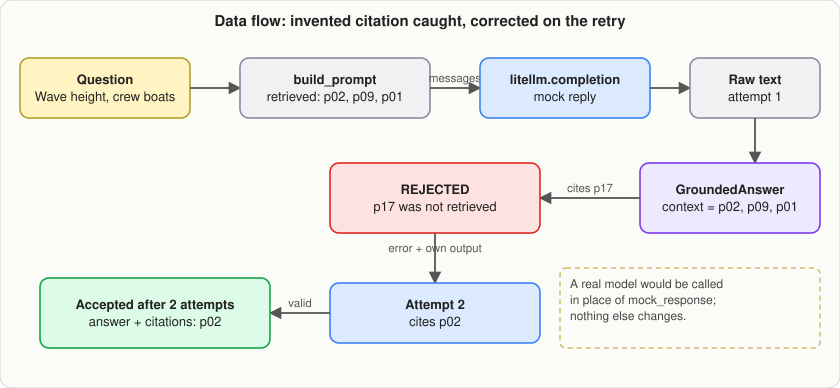

In [10]:
diagram(840, 388, [
    ("box", 20, 58, 170, 60, "Question\nWave height, crew boats", "gold"),
    ("arrow", 190, 88, 240, 88, ""),
    ("box", 240, 58, 190, 60, "build_prompt\nretrieved: p02, p09, p01", "grey"),
    ("arrow", 430, 88, 480, 88, "messages"),
    ("box", 480, 58, 170, 60, "litellm.completion\nmock reply", "blue"),
    ("arrow", 650, 88, 690, 88, ""),
    ("box", 690, 58, 130, 60, "Raw text\nattempt 1", "grey"),
    ("arrow", 755, 118, 755, 163, ""),
    ("box", 640, 163, 180, 70, "GroundedAnswer\ncontext = p02, p09, p01", "violet"),
    ("arrow", 640, 198, 540, 198, "cites p17"),
    ("box", 330, 163, 210, 70, "REJECTED\np17 was not retrieved", "red"),
    ("arrow", 435, 233, 435, 283, "error + own output"),
    ("box", 330, 283, 210, 60, "Attempt 2\ncites p02", "blue"),
    ("arrow", 330, 313, 270, 313, "valid"),
    ("box", 40, 278, 230, 70, "Accepted after 2 attempts\nanswer + citations: p02", "green"),
    ("note", 560, 268, 260, 80, "A real model would be called\nin place of mock_response;\nnothing else changes."),
], "Data flow: invented citation caught, corrected on the retry")

In [11]:
# the same retry loop, now with the grounding check: the model first invents a citation, then corrects it
invented = '{"answer": "No sailing above 1.5 m.", "citations": ["p17"]}'
corrected = '{"answer": "No sailing above 1.5 m.", "citations": ["p02"]}'
prompt = build_prompt("What wave height stops the crew boats from sailing?", retrieved)
obj, attempts = structured_call(GroundedAnswer, prompt, [invented, corrected], context={"retrieved": retrieved})
print(f"accepted after {attempts} attempt(s): {obj}")

accepted after 2 attempt(s): answer='No sailing above 1.5 m.' citations=['p02'] refused=False


A grounded schema catches *fabricated references and missing evidence*; it cannot tell whether passage
`p02` really supports the sentence. That is a different check (faithfulness), done by a judge model in
module 07 and, continuously, by the supervisor of module 08. Layer them: types and grounding are free and
instant, judging costs a model call.

### Optional: the same call against a real model

If you have credentials you can point the unchanged code at a hosted model. The cell below only runs when
you set `RAG_LIVE_MODEL` (for example `bedrock/eu.amazon.nova-lite-v1:0`); the executed notebook does not set
it, so it prints a notice and makes no network call.

In [12]:
live_model = os.environ.get("RAG_LIVE_MODEL")
if live_model:
    r = litellm.completion(model=live_model, messages=build_prompt("What wave height stops the crew boats from sailing?", retrieved)
                           + [{"role": "user", "content": 'Reply ONLY with JSON: {"answer": str, "citations": [ids], "refused": bool}'}])
    print(GroundedAnswer.model_validate_json(extract_json(r.choices[0].message.content), context={"retrieved": retrieved}))
else:
    print("RAG_LIVE_MODEL is not set: skipping the real call (everything above ran offline).")

RAG_LIVE_MODEL is not set: skipping the real call (everything above ran offline).


### A note from practice: when LiteLLM is not the right layer

LiteLLM normalises *text* chat well. In the wind-farm agent, image input to Amazon Nova through LiteLLM was
inconsistent, so the vision call used the Bedrock Converse API directly while all text calls stayed on
LiteLLM. A routing layer is a convenience for the common path, not a wall: keep an escape hatch to the native
client for the one feature the abstraction does not cover, and keep that exception in one small function.

## Exercises

1. Add `confidence: float = Field(ge=0, le=1)` to `GroundedAnswer`. Which of the canned replies in section 6
   now fail, and what error message does the retry loop send back to the model?
2. Raise the simulated slip rate in section 5 to 50% and `max_attempts` to 5. Does the measured failure rate
   follow `0.5 ** 5`? What does that say about relying on retries for a model that is mostly wrong?
3. Add a third deployment to the `Router` and a second fallback. Make the first backup also fail
   (`mock_response="litellm.Timeout"`) and confirm the request is served by the second.
4. Compute the monthly cost of 20,000 questions a month at 3 and at 8 retrieved passages for each model
   in section 3. At what point does a cheaper model beat a better retriever on cost, and on quality?